In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms

import seaborn as sns
import os
import datetime
import pickle


from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from scipy.stats import entropy

from scipy.stats import ranksums, ttest_ind, f_oneway, false_discovery_control
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils

### Supporting functions

In [5]:
# updated on 7/16/2026
def szred_to_responder(rednum):
    if rednum > 0.9:
        return 'SR'
    elif rednum < 0.5:
        return 'NR'
    else:
        return 'IR'

### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)
patcodesdf['seizure_rate'] = patcodesdf['baseline_seizure_rate'] * (1 - patcodesdf['sz_red'])
patcodesdf['log_seizure_rate'] = np.log(patcodesdf['seizure_rate'] + (np.exp(-3.5) * (patcodesdf['seizure_rate'] == 0)))
patcodesdf['log_baseline_seizure_rate'] = np.log(patcodesdf['baseline_seizure_rate'])

patcodesdf['Responder_Type'] = patcodesdf['sz_red'].apply(lambda x: szred_to_responder(x))

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red', 'log_baseline_seizure_rate', 'log_seizure_rate']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['Responder_Type'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].Responder_Type.item()
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
patcodesdf.loc[(patcodesdf['npe_code'].isin(patient_list))].Responder_Type.value_counts()

Responder_Type
IR    20
NR    10
SR     8
Name: count, dtype: int64

In [11]:
sorted_patient_list = patcodesdf.loc[patcodesdf['npe_code'].isin(patient_list)].sort_values(by='sz_red', 
                                                                                            ascending=False)['npe_code'].to_list()

In [12]:
response_color_dict = {'SR':'tab:blue', 'IR':'purple', 'NR':'tab:red'}
pat_response_colors = {key: response_color_dict[patcodesdf.loc[patcodesdf['npe_code']==key].Responder_Type.item()] 
                       for key in sorted_patient_list}

## Stimulation count trend by group

In [13]:
mcountdf = []

for patient_id in patient_list[:]:
    tdf = dfdict[patient_id].copy()
    tdf = tdf.groupby(by='Local_hour').agg(stim_count=('Episode starts with RX', 'mean'),
                                           Responder_Type=('Responder_Type', 'first'), 
                                           sz_red=('sz_red', 'first')).reset_index()
    # hour relative to  max hour
    tdf['Local_hour_maxrel'] =  ( (tdf['Local_hour'] - tdf.loc[tdf['stim_count'].idxmax()]['Local_hour'] + 12) % 24 ) - 12
    tdf.insert(loc=0, column='npecode', value=patient_id) # insert patient name
    # repeat -12h at 12hr for plotting
    new_row = tdf.loc[tdf['Local_hour_maxrel'] == -12].copy()
    new_row['Local_hour_maxrel'] = 12
    tdf = pd.concat([tdf, new_row], ignore_index=True)
    
    # append
    mcountdf.append(tdf)

# convert to dataframe
mcountdf = pd.concat(mcountdf, ignore_index=True, axis=0)

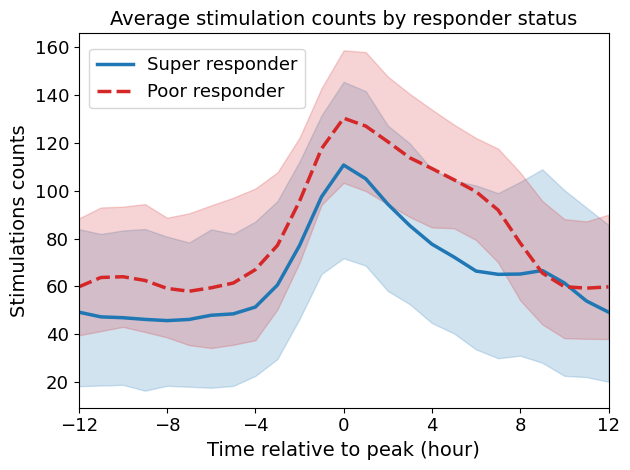

In [14]:
ax = sns.lineplot(data=mcountdf.loc[mcountdf['Responder_Type']!='IR'], 
                  x='Local_hour_maxrel', y='stim_count', hue='Responder_Type',
                  palette=response_color_dict, hue_order=['SR', 'NR'], 
                  style='Responder_Type', linewidth=2.5)
plt.xlim([-12,12])

plt.title('Average stimulation counts by responder status', fontsize=14)
plt.xlabel('Time relative to peak (hour)', fontsize=14)
plt.ylabel('Stimulations counts', fontsize=14)
plt.xticks(ticks=[-12,-8,-4,0,4,8,12])
plt.tick_params(labelsize=13)

leg_handles, leg_labels = ax.get_legend_handles_labels()
leg_labels = ['Super responder', 'Poor responder']
ax.legend(handles=leg_handles, labels=leg_labels, fontsize=13, loc=[0.02,0.8])

plt.tight_layout()
if save_flag:
    plt.savefig(outsupfig_dir + 'stim_count_mean_by_group_maxrel.pdf', dpi=300)

plt.show()

### Total stimulation scatterplot

In [15]:
totavgdf = mcountdf.groupby(by='npecode').agg(tot_stim=('stim_count', 'sum'), sz_red=('sz_red', 'first')).reset_index()

PearsonRResult(statistic=-0.289776763685565, pvalue=0.07761162815846057)


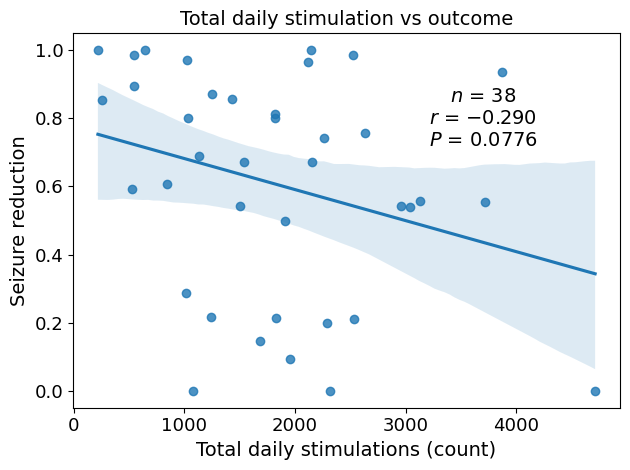

In [16]:
# statistical analysis
pearout = pearsonr(totavgdf['sz_red'], totavgdf['tot_stim'])
print(pearout)

ax = sns.regplot(data=totavgdf, x='tot_stim', y='sz_red')
plt.text(x=0.75, y=0.7, s=f'$n$ = %d\n$r$ = $%0.3f$\n$P$ = $%0.4f$'%(totavgdf.shape[0], pearout.statistic, pearout.pvalue), 
         transform=ax.transAxes, ha='center', fontsize=14)
plt.xlabel('Total daily stimulations (count)', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.title(f"Total daily stimulation vs outcome", fontsize=14)
plt.tick_params(labelsize=13)

plt.tight_layout()
if save_flag:
    plt.savefig(outsupfig_dir + 'stim_totalstim_scatter.pdf', dpi=300)

plt.show()